# Data Exploration

Explore dataset structure, image properties, class distribution, and sample images.


In [1]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()
print(f"Working directory: {PROJECT_ROOT.resolve()}")


Working directory: /content


In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from pathlib import Path

DATASET_ZIP = Path(
    "/content/drive/MyDrive/Industrial-Vision-AI/data/raw/mvtec-ad.zip"
)

print(f"Dataset archive exists: {DATASET_ZIP.exists()}")

Dataset archive exists: True


In [4]:
file_size_bytes = DATASET_ZIP.stat().st_size
file_size_gib = file_size_bytes / (1024 ** 3)

print(f"File size: {file_size_gib:.2f} GiB")

File size: 4.92 GiB


In [5]:
import shutil

disk_usage = shutil.disk_usage("/content")

free_space_gib = disk_usage.free / (1024 ** 3)
total_space_gib = disk_usage.total / (1024 ** 3)

print(f"Total disk space: {total_space_gib:.2f} GiB")
print(f"Free disk space: {free_space_gib:.2f} GiB")

Total disk space: 107.72 GiB
Free disk space: 87.20 GiB


In [6]:
import zipfile

with zipfile.ZipFile(DATASET_ZIP, "r") as archive:
    archive_files = archive.namelist()

print(f"Total entries in archive: {len(archive_files)}")
print("\nFirst 10 entries:")

for file_name in archive_files[:10]:
    print(file_name)

Total entries in archive: 40010

First 10 entries:
mvtec-ad/
__MACOSX/._mvtec-ad
mvtec-ad/samples.json
__MACOSX/mvtec-ad/._samples.json
mvtec-ad/dataset_preview.jpg
__MACOSX/mvtec-ad/._dataset_preview.jpg
mvtec-ad/metadata.json
__MACOSX/mvtec-ad/._metadata.json
mvtec-ad/README.md
__MACOSX/mvtec-ad/._README.md


In [7]:
import json
import zipfile

with zipfile.ZipFile(DATASET_ZIP, "r") as archive:
    samples_json = archive.read("mvtec-ad/samples.json")

samples_data = json.loads(samples_json)

print(f"Data type: {type(samples_data).__name__}")
print(f"Top-level keys: {list(samples_data.keys())}")

Data type: dict
Top-level keys: ['samples']


In [8]:
samples = samples_data["samples"]

print(f"Samples type: {type(samples).__name__}")
print(f"Number of samples: {len(samples)}")

Samples type: list
Number of samples: 5354


In [9]:
first_sample = samples[0]

print(f"First sample type: {type(first_sample).__name__}")
print(f"First sample keys: {list(first_sample.keys())}")

First sample type: dict
First sample keys: ['_id', 'filepath', 'tags', '_media_type', '_rand', 'category', 'defect', 'split', '_dataset_id']


In [10]:
print(f"Filepath: {first_sample['filepath']}")
print(f"Category: {first_sample['category']}")
print(f"Defect: {first_sample['defect']}")
print(f"Split: {first_sample['split']}")

Filepath: data/data_0/176.png
Category: {'_id': {'$oid': '6621d768324f6e05d5834b50'}, '_cls': 'Classification', 'tags': [], 'label': 'transistor'}
Defect: {'_id': {'$oid': '6621d768324f6e05d5834b51'}, '_cls': 'Classification', 'tags': [], 'label': 'good'}
Split: train


In [11]:
image_path = first_sample["filepath"]
category_label = first_sample["category"]["label"]
defect_label = first_sample["defect"]["label"]
dataset_split = first_sample["split"]

print(f"Image path: {image_path}")
print(f"Category: {category_label}")
print(f"Defect: {defect_label}")
print(f"Split: {dataset_split}")

Image path: data/data_0/176.png
Category: transistor
Defect: good
Split: train


In [12]:
categories = []

for sample in samples:
    category = sample["category"]["label"]
    categories.append(category)

unique_categories = sorted(set(categories))

print(f"Number of unique categories: {len(unique_categories)}")
print(f"Categories: {unique_categories}")

Number of unique categories: 15
Categories: ['bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper']


In [13]:
from collections import Counter

category_counts = Counter(categories)

for category, count in sorted(category_counts.items()):
    print(f"{category}: {count}")

bottle: 292
cable: 374
capsule: 351
carpet: 397
grid: 342
hazelnut: 501
leather: 369
metal_nut: 335
pill: 434
screw: 480
tile: 347
toothbrush: 102
transistor: 313
wood: 326
zipper: 391


In [14]:
defect_labels = []

for sample in samples:
    defect_label = sample["defect"]["label"]
    defect_labels.append(defect_label)

defect_counts = Counter(defect_labels)

for defect_label, count in sorted(defect_counts.items()):
    print(f"{defect_label}: {count}")

bent: 37
bent_lead: 10
bent_wire: 13
broken: 12
broken_large: 20
broken_small: 22
broken_teeth: 19
cable_swap: 12
color: 93
combined: 55
contamination: 42
crack: 84
cut: 53
cut_inner_insulation: 14
cut_lead: 10
cut_outer_insulation: 10
damaged_case: 10
defective: 30
fabric_border: 17
fabric_interior: 16
faulty_imprint: 41
flip: 23
fold: 17
glue: 30
glue_strip: 18
good: 4096
gray_stroke: 16
hole: 45
liquid: 10
manipulated_front: 24
metal_contamination: 28
misplaced: 10
missing_cable: 12
missing_wire: 10
oil: 18
pill_type: 9
poke: 39
poke_insulation: 10
print: 17
rough: 32
scratch: 91
scratch_head: 24
scratch_neck: 25
split_teeth: 18
squeeze: 20
squeezed_teeth: 16
thread: 30
thread_side: 23
thread_top: 23


In [15]:
split_labels = []

for sample in samples:
    split_label = sample["split"]
    split_labels.append(split_label)

split_counts = Counter(split_labels)

for split_label, count in sorted(split_counts.items()):
    print(f"{split_label}: {count}")

test: 1725
train: 3629


In [16]:
train_defective_count = 0

for sample in samples:
    if sample["split"] == "train" and sample["defect"]["label"] != "good":
        train_defective_count += 1

print(f"Defective training samples: {train_defective_count}")

Defective training samples: 0


In [17]:
test_good_count = 0

for sample in samples:
    if sample["split"] == "test" and sample["defect"]["label"] == "good":
        test_good_count += 1

print(f"Good test samples: {test_good_count}")

Good test samples: 467


In [18]:
first_image_path = first_sample["filepath"]
archive_image_path = f"mvtec-ad/{first_image_path}"

print(f"Image path from metadata: {first_image_path}")
print(f"Full path inside archive: {archive_image_path}")

Image path from metadata: data/data_0/176.png
Full path inside archive: mvtec-ad/data/data_0/176.png


In [19]:
with zipfile.ZipFile(DATASET_ZIP, "r") as archive:
    image_exists = archive_image_path in archive.namelist()

print(f"Image exists in archive: {image_exists}")

Image exists in archive: True


In [20]:
from io import BytesIO
from PIL import Image
import zipfile

with zipfile.ZipFile(DATASET_ZIP, "r") as archive:
    image_bytes = archive.read(archive_image_path)

image = Image.open(BytesIO(image_bytes))

print(f"Image format: {image.format}")
print(f"Image mode: {image.mode}")
print(f"Image size: {image.size}")

Image format: PNG
Image mode: RGB
Image size: (1024, 1024)


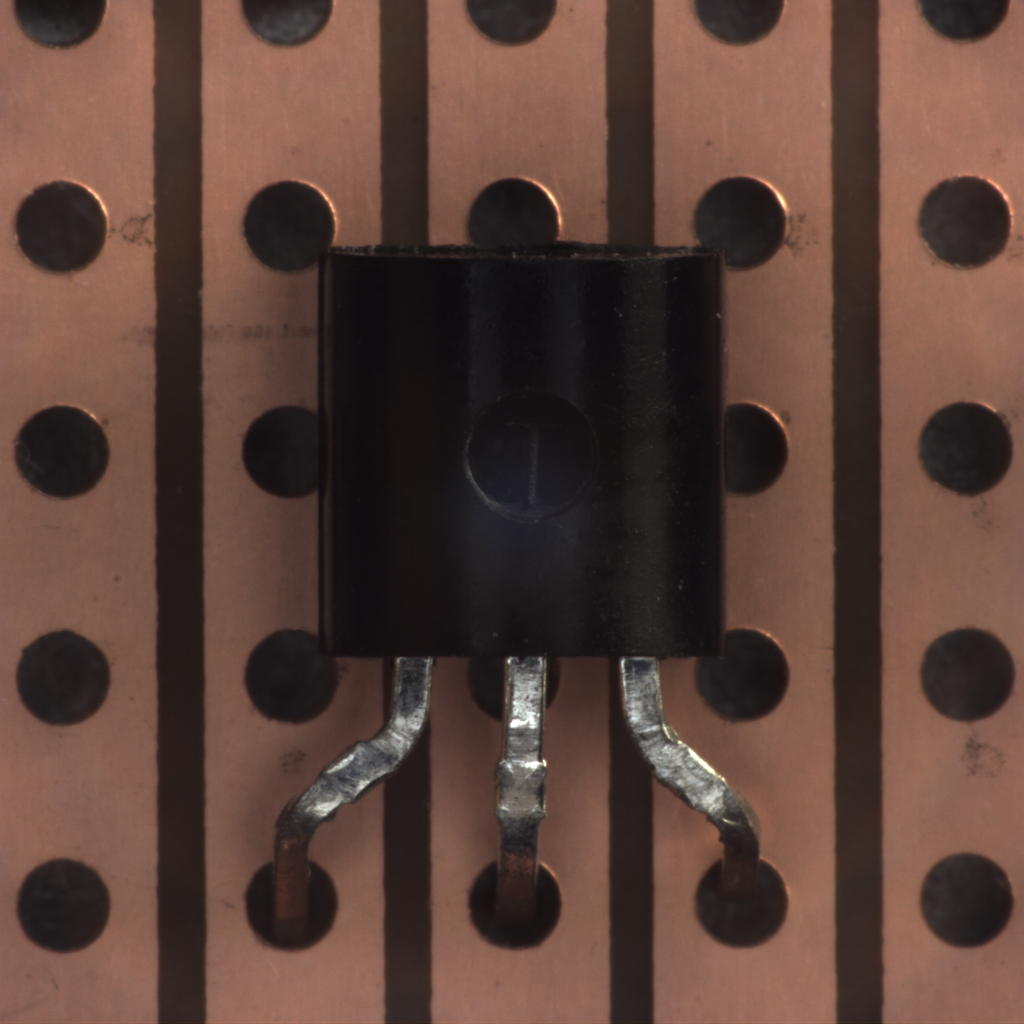

In [21]:
from IPython.display import display

display(image)

In [22]:
first_defective_sample = None

for sample in samples:
    if sample["defect"]["label"] != "good":
        first_defective_sample = sample
        break

print(f"Category: {first_defective_sample['category']['label']}")
print(f"Defect: {first_defective_sample['defect']['label']}")
print(f"Split: {first_defective_sample['split']}")
print(f"Filepath: {first_defective_sample['filepath']}")

Category: transistor
Defect: damaged_case
Split: test
Filepath: data/data_2/002-2.png


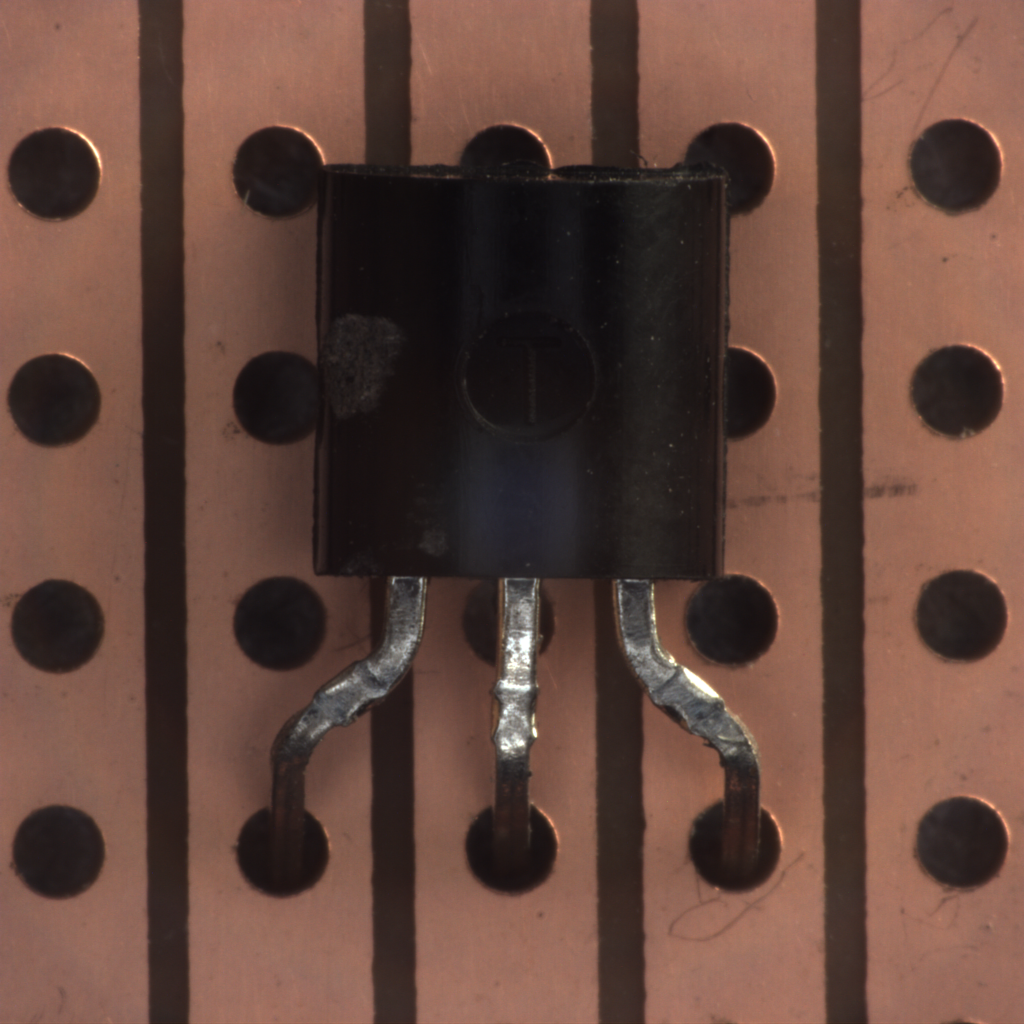

In [23]:
defective_image_path = first_defective_sample["filepath"]
defective_archive_path = f"mvtec-ad/{defective_image_path}"

with zipfile.ZipFile(DATASET_ZIP, "r") as archive:
    defective_image_bytes = archive.read(defective_archive_path)

defective_image = Image.open(BytesIO(defective_image_bytes))

display(defective_image)

In [24]:
print(f"Sample keys: {list(first_defective_sample.keys())}")
print(f"Defect mask information: {first_defective_sample.get('defect_mask')}")

Sample keys: ['_id', 'filepath', 'tags', '_media_type', '_rand', 'category', 'defect', 'split', 'defect_mask', '_dataset_id']
Defect mask information: {'_id': {'$oid': '6621d768324f6e05d5834cfc'}, '_cls': 'Segmentation', 'tags': [], 'mask_path': 'fields/defect_mask/defect_mask_0/002_mask.png'}


In [25]:
mask_path = first_defective_sample["defect_mask"]["mask_path"]
archive_mask_path = f"mvtec-ad/{mask_path}"

with zipfile.ZipFile(DATASET_ZIP, "r") as archive:
    mask_exists = archive_mask_path in archive.namelist()

print(f"Mask path from metadata: {mask_path}")
print(f"Full path inside archive: {archive_mask_path}")
print(f"Mask exists in archive: {mask_exists}")

Mask path from metadata: fields/defect_mask/defect_mask_0/002_mask.png
Full path inside archive: mvtec-ad/fields/defect_mask/defect_mask_0/002_mask.png
Mask exists in archive: True


In [26]:
with zipfile.ZipFile(DATASET_ZIP, "r") as archive:
    mask_bytes = archive.read(archive_mask_path)

mask_image = Image.open(BytesIO(mask_bytes))

print(f"Mask format: {mask_image.format}")
print(f"Mask mode: {mask_image.mode}")
print(f"Mask size: {mask_image.size}")

Mask format: PNG
Mask mode: L
Mask size: (1024, 1024)


In [27]:
import numpy as np

mask_array = np.array(mask_image)
unique_values = np.unique(mask_array)

print(f"Mask array shape: {mask_array.shape}")
print(f"Unique pixel values: {unique_values}")
print(f"Number of unique values: {len(unique_values)}")

Mask array shape: (1024, 1024)
Unique pixel values: [  0 255]
Number of unique values: 2


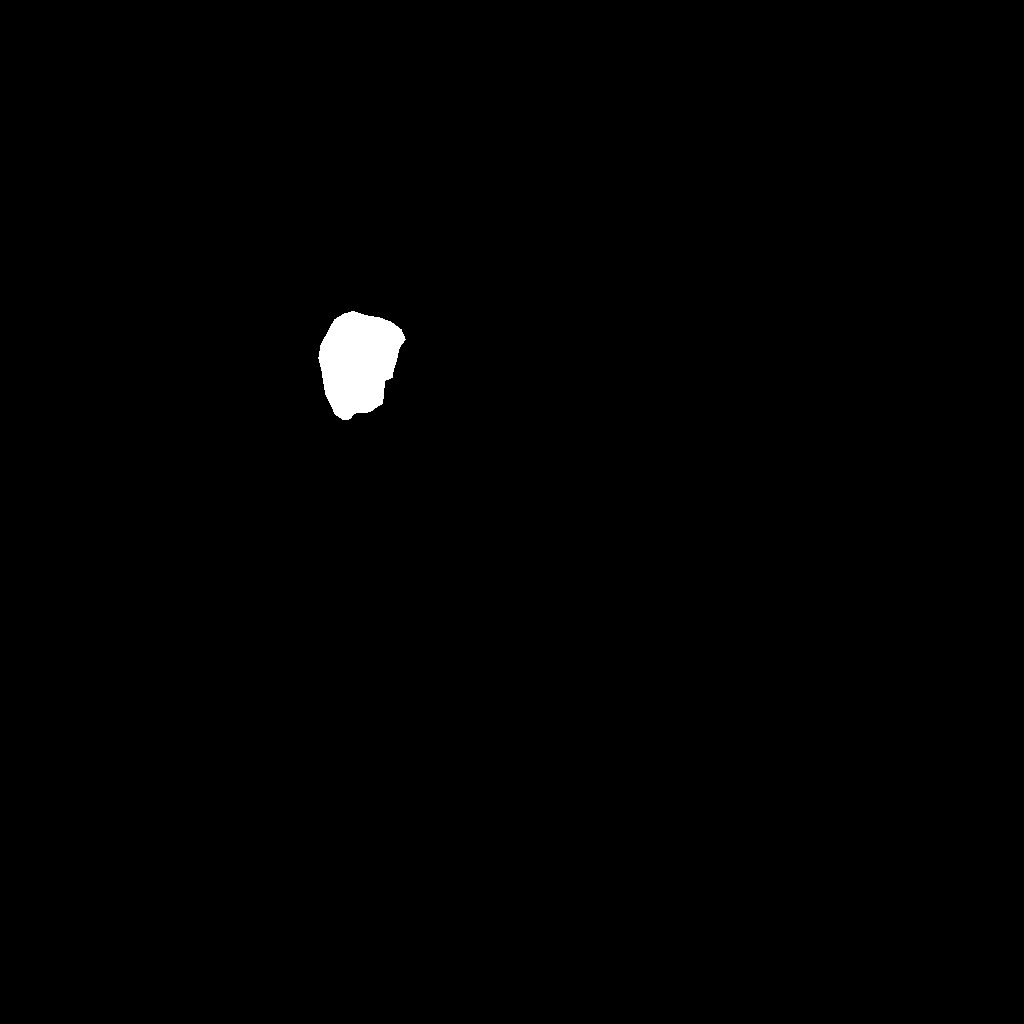

In [28]:
display(mask_image)

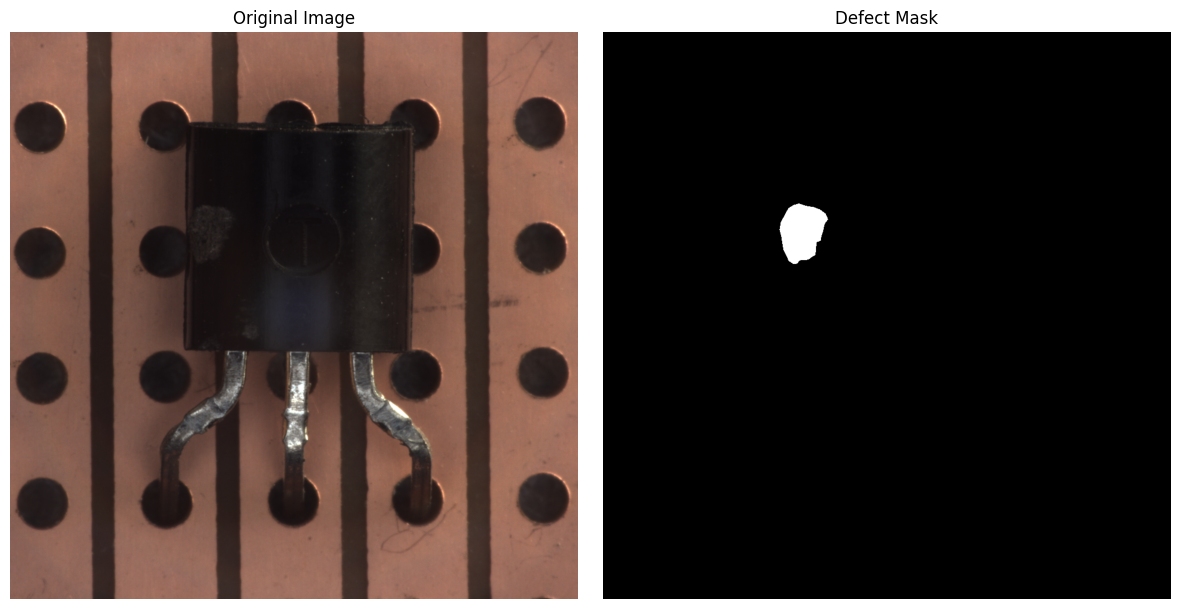

In [29]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(defective_image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(mask_image, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Defect Mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [30]:
defect_pixels = np.sum(mask_array == 255)
total_pixels = mask_array.size
defect_percentage = (defect_pixels / total_pixels) * 100

print(f"Defect pixels: {defect_pixels}")
print(f"Total pixels: {total_pixels}")
print(f"Defect area percentage: {defect_percentage:.4f}%")

Defect pixels: 6642
Total pixels: 1048576
Defect area percentage: 0.6334%


In [31]:
normal_pixels = np.sum(mask_array == 0)

print(f"Non-defect pixels: {normal_pixels}")
print(f"Check total: {normal_pixels + defect_pixels}")

Non-defect pixels: 1041934
Check total: 1048576


In [32]:
selected_samples = []
selected_categories = set()

for sample in samples:
    if sample["defect"]["label"] != "good":
        category = sample["category"]["label"]

        if category not in selected_categories:
            selected_samples.append(sample)
            selected_categories.add(category)

        if len(selected_samples) == 3:
            break

for index, sample in enumerate(selected_samples, start=1):
    print(f"Sample {index}")
    print(f"  Category: {sample['category']['label']}")
    print(f"  Defect: {sample['defect']['label']}")
    print(f"  Split: {sample['split']}")
    print(f"  Image path: {sample['filepath']}")
    print()

Sample 1
  Category: transistor
  Defect: damaged_case
  Split: test
  Image path: data/data_2/002-2.png

Sample 2
  Category: wood
  Defect: color
  Split: test
  Image path: data/data_5/002-8.png

Sample 3
  Category: capsule
  Defect: crack
  Split: test
  Image path: data/data_8/002-15.png



In [33]:
for index, sample in enumerate(selected_samples, start=1):
    mask_path = sample["defect_mask"]["mask_path"]
    archive_mask_path = f"mvtec-ad/{mask_path}"

    with zipfile.ZipFile(DATASET_ZIP, "r") as archive:
        mask_exists = archive_mask_path in archive.namelist()

    print(f"Sample {index}: {sample['category']['label']}")
    print(f"Defect: {sample['defect']['label']}")
    print(f"Mask path: {mask_path}")
    print(f"Mask exists: {mask_exists}")
    print()

Sample 1: transistor
Defect: damaged_case
Mask path: fields/defect_mask/defect_mask_0/002_mask.png
Mask exists: True

Sample 2: wood
Defect: color
Mask path: fields/defect_mask/defect_mask_0/002_mask-5.png
Mask exists: True

Sample 3: capsule
Defect: crack
Mask path: fields/defect_mask/defect_mask_1/002_mask-10.png
Mask exists: True

